# Cell Reprogramming

> Author: Ruowen Xiao
>
> Created on: 2026-10-15

## 1. Introduction

Simulation of a simple pluripotency network

![The transcription factors circuit](https://media.springernature.com/full/springer-static/image/art%3A10.1038%2Fsrep25438/MediaObjects/41598_2016_Article_BFsrep25438_Fig1_HTML.jpg?as=webp)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from dataclasses import dataclass
from scipy.integrate import solve_ivp

## 2. Implementation

### 2.1. Parameters Preparation

In [2]:
@dataclass
class ModelParams:
    N_over: float
    O_over: float
    T_over: float

    LIF: float

    p_N: float
    p_O: float
    p_T: float

    n: int

    K_O: float
    K_d: float
    K_NT: float

In [3]:
params_0 = ModelParams(
    N_over=0,
    O_over=0,
    T_over=0.05,
    LIF=0,

    p_N=1,
    p_O=1,
    p_T=1,
    n=2,
    K_d=0.1,
    K_O=0.3,
    K_NT=0.2
)
params_0

ModelParams(N_over=0, O_over=0, T_over=0.05, LIF=0, p_N=1, p_O=1, p_T=1, n=2, K_O=0.3, K_d=0.1, K_NT=0.2)

In [4]:
params_N = ModelParams(
    N_over=0.3,
    O_over=0,
    T_over=0.05,
    LIF=0.06,  # TODO: check if LIF is on

    p_N=1,
    p_O=1,
    p_T=1,
    n=2,
    K_d=0.1,
    K_O=0.3,
    K_NT=0.2
)
params_N

ModelParams(N_over=0.3, O_over=0, T_over=0.05, LIF=0.06, p_N=1, p_O=1, p_T=1, n=2, K_O=0.3, K_d=0.1, K_NT=0.2)

In [5]:
params_O = ModelParams(
    N_over=0,
    O_over=0.3,
    T_over=0.05,
    LIF=0.06,

    p_N=1,
    p_O=1,
    p_T=1,
    n=2,
    K_d=0.1,
    K_O=0.3,
    K_NT=0.2
)
params_O

ModelParams(N_over=0, O_over=0.3, T_over=0.05, LIF=0.06, p_N=1, p_O=1, p_T=1, n=2, K_O=0.3, K_d=0.1, K_NT=0.2)

In [6]:
params_T = ModelParams(
    N_over=0,
    O_over=0,
    T_over=0.3,
    LIF=0.06,

    p_N=1,
    p_O=1,
    p_T=1,
    n=2,
    K_d=0.1,
    K_O=0.3,
    K_NT=0.2
)
params_T

ModelParams(N_over=0, O_over=0, T_over=0.3, LIF=0.06, p_N=1, p_O=1, p_T=1, n=2, K_O=0.3, K_d=0.1, K_NT=0.2)

In [7]:
params_1 = ModelParams(
    N_over=0,
    O_over=0,
    T_over=0.05,
    LIF=0.06,

    p_N=1,
    p_O=1,
    p_T=1,
    n=2,
    K_d=0.1,
    K_O=0.3,
    K_NT=0.2
)
params_1

ModelParams(N_over=0, O_over=0, T_over=0.05, LIF=0.06, p_N=1, p_O=1, p_T=1, n=2, K_O=0.3, K_d=0.1, K_NT=0.2)

### 2.2 Modeling

Expression of the complex $[N \vert T]$:

TODO: write equations

In [8]:
def NT(N_total, T_total, K_d):
    a = 1
    b = - (N_total + T_total + K_d)
    c = N_total * T_total
    return (- b - np.sqrt(b**2 - 4 * a * c)) / (2 * a)

Activator Hill equation:

$$A[T] = \frac{[T]^n}{K_A^n + [T]^n} = \frac{(\frac{[T]}{K_A})^n}{1 + (\frac{[T]}{K_A})^n}$$

In [9]:
def hill(activator, K, n):
    temp_term = (activator / K)**n
    return temp_term / (1 + temp_term)

system of ODEs:

$$\begin{cases}
\displaystyle \frac{\partial [N_{total}]}{\partial t} = N_{over} + LIF &+ p_N \cdot A([O_{total}], [N_{total}]) &- [N_{total}] \\
\displaystyle \frac{\partial [O_{total}]}{\partial t} = O_{over} + LIF &+ p_O \cdot A([O_{total}], [O_{total}]) \cdot A([N \vert T], [O_{total}]) &- [O_{total}] \\
\displaystyle \frac{\partial [T_{total}]}{\partial t} = T_{over} &+ p_T \cdot A([O_{total}], [T_{total}]) \cdot A([N \vert T], [T_{total}]) &- [T_{total}] \\
\end{cases}$$

$$Y = \begin{pmatrix}
[N_{total}] \\
[O_{total}] \\
[T_{total}] \\
\end{pmatrix}$$

In [10]:
def is_pluripotent(Y):
    for y in Y:
        if y < 0.5:
            return False
    return True

In [11]:
def f(t, Y, p: ModelParams, check_pluripotent=False):
    y_N, y_O, y_T = Y

    hill_O = hill(y_O, p.K_O, 1)
    hill_NT = hill(NT(y_N, y_T, p.K_d), p.K_NT, p.n)

    LIF = 0 if check_pluripotent and not is_pluripotent(Y) else p.LIF

    dyNdt = p.N_over + LIF + p.p_N * hill_O           - y_N
    dyOdt = p.O_over + LIF + p.p_O * hill_O * hill_NT - y_O
    dyTdt = p.T_over       + p.p_T * hill_O * hill_NT - y_T

    return [dyNdt, dyOdt, dyTdt]

### 2.3 Simulation

Three reprogramming scenarios:

1. exogenous Oct4 present and then removed

2. exogenous Nanog expressed and then removed

3. Tet1 over expressed and then the exogenous Tet1 is turned off

In [12]:
def simulate(params):
    Y = {
        "Nanog": [],
        "Oct4": [],
        "Tet1": []
    }

    for i, p in enumerate(params):
        if i == 0:
            y0 = [p.N_over, p.O_over, p.T_over]
        else:
            y0 = [y[-1] for y in Y.values()]

        check_pluripopent = True if p==params_1 else False

        sol = solve_ivp(
            fun=f,
            t_span=(0, 20),
            y0=y0,
            method="RK45",
            t_eval=np.linspace(0, 20, 100),
            args=(p, check_pluripopent)
        )

        for j, (key, val) in enumerate(Y.items()):
            Y[key] = np.append(val, sol.y[j])

    return Y

In [13]:
def plot_expression_level(Y, x_label):
    fig, ax = plt.subplots()
    for key, val in Y.items():
        ax.plot(np.arange(len(val)), val, label=key)
    ax.legend()
    ax.axhline(y=0.2, linestyle="--", color="gray")
    ax.axhline(y=0.5, linestyle="--", color="gray")
    ax.set_xlabel(x_label)
    ax.set_ylabel("Expression Level")
    plt.show()

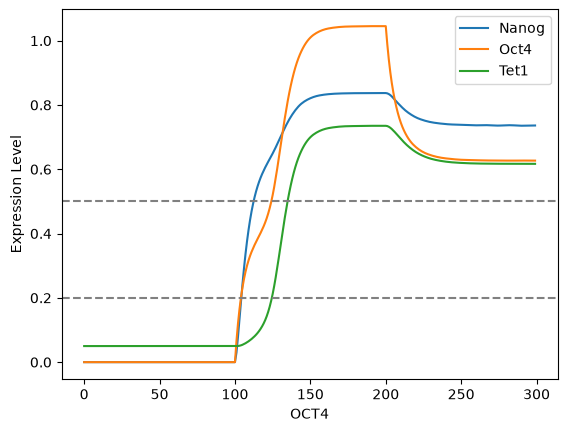

In [14]:
Y1 = simulate([params_0, params_O, params_1])
plot_expression_level(Y1, "OCT4")

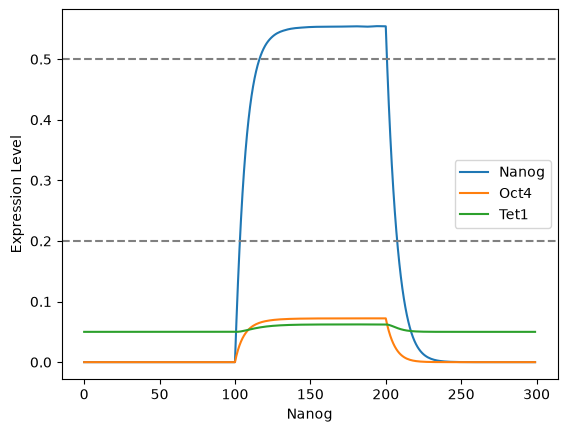

In [15]:
Y2 = simulate([params_0, params_N, params_1])
plot_expression_level(Y2, "Nanog")

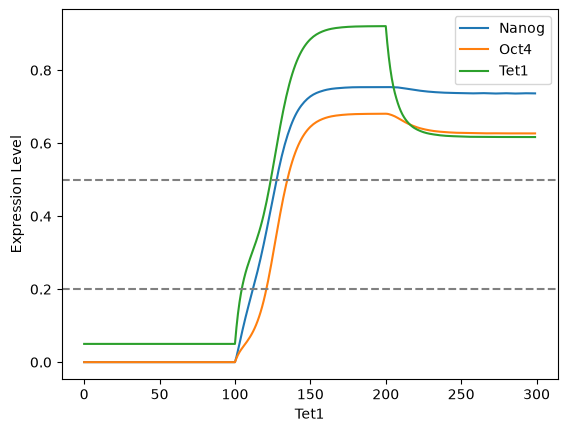

In [16]:
Y3 = simulate([params_0, params_T, params_1])
plot_expression_level(Y3, "Tet1")

In [17]:
Y = {}
dicts = [Y1, Y2, Y3]

for i, key in enumerate(Y1):
    Y[key] = np.concatenate([d[key] for d in dicts])

lengths = [len(d["Nanog"]) for d in dicts]
boundaries = np.cumsum(lengths)[:-1]

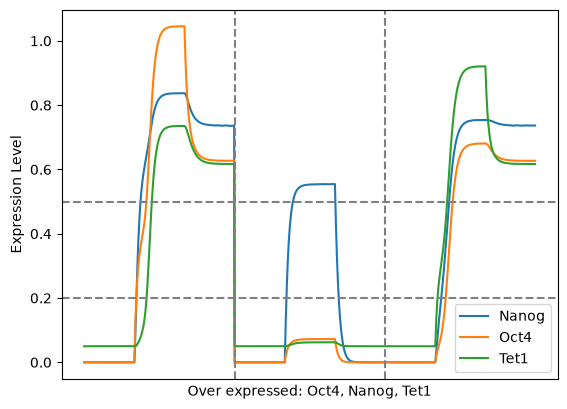

In [18]:
fig, ax = plt.subplots()

for key, val in Y.items():
    ax.plot(np.arange(len(val)), val, label=key)

ax.axhline(y=0.2, linestyle="--", color="gray")
ax.axhline(y=0.5, linestyle="--", color="gray")
for boundary in boundaries:
    ax.axvline(x=boundary, linestyle="--", color="gray")

ax.legend()
ax.set_xticks([])
ax.set_xlabel("Over expressed: Oct4, Nanog, Tet1")
ax.set_ylabel("Expression Level")
plt.show()

???